# 1. Introduction

This project focuses on using machine learning to predict whether a bank customer will subscribe to a term deposit after being contacted during a marketing campaign.

The project uses the Bank Marketing dataset obtained from the UCI Machine Learning Repository. Since the target variable indicates whether the customer subscribed to a term deposit, this problem is treated as a supervised binary classification problem.

The main objective is to preprocess the dataset, explore customer and campaign-related factors, develop multiple machine learning classification models, evaluate their performance, and identify the most suitable model for predicting customer subscription outcomes.

# 2. Business Problem

Banks conduct marketing campaigns to encourage customers to subscribe to term deposit products. However, contacting every customer can require significant time and resources.

The business problem is to predict whether a customer is likely to subscribe to a term deposit based on available customer and campaign information. A machine learning model can help the bank identify customers who are more likely to respond positively to marketing campaigns.

This can support more targeted marketing decisions, reduce unnecessary customer contacts, and improve the efficiency of marketing campaigns.

# 3. Dataset Description

The Bank Marketing dataset is a publicly available dataset obtained from the UCI Machine Learning Repository. It contains information collected from direct marketing campaigns conducted by a Portuguese banking institution.

The dataset contains customer demographic information, financial information, and details related to previous marketing contacts. The target variable `y` indicates whether the customer subscribed to a bank term deposit.

The problem is formulated as a supervised binary classification task, where the machine learning models will predict one of two outcomes: `yes` or `no`.



In [1]:

## 3.1  Dataset Loading
import pandas as pd

df = pd.read_csv("bank-full.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
## 3.2 Dataset Structure and Data Types
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (45211, 17)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data Types:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


In [3]:
## 4. Data Preprocessing
## 4.1 Check for missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [4]:
## 4.2 Check for duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [5]:
## 4.2.1 Check 'unknown' values in categorical columns
cat_check = df.select_dtypes(include=["object", "str"]).columns
for col in cat_check:
    n = (df[col] == "unknown").sum()
    if n > 0:
        print(f"{col}: {n} ({n / len(df) * 100:.2f}%)")

job: 288 (0.64%)
education: 1857 (4.11%)
contact: 13020 (28.80%)
poutcome: 36959 (81.75%)


In [6]:
## 4.3 Select numerical columns
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Columns:")
print(numeric_columns.tolist())

Numerical Columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [7]:
## 4.4 Check for outliers using the IQR (Interquartile Range) method
Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

outlier_counts = ((df[numeric_columns] < (Q1 - 1.5 * IQR)) |
                   (df[numeric_columns] > (Q3 + 1.5 * IQR))).sum()

print("Outlier counts:")
print(outlier_counts)

Outlier counts:
age          487
balance     4729
day            0
duration    3235
campaign    3064
pdays       8257
previous    8257
dtype: int64


## 4.4.1  Outlier Detection Interpretation
The Interquartile Range (IQR) method was used to identify potential outliers in the numerical variables. The results showed that some variables contained values outside the normal IQR range. The highest number of potential outliers was observed in `pdays` and `previous`, while `day` had no detected outliers.

However, the detected values were not automatically removed because some extreme values may represent meaningful customer information rather than errors. For example, `pdays = -1` is a valid value in the dataset and indicates that the customer was not previously contacted. Therefore, removing these values based only on the IQR method could result in the loss of useful information.

The outlier analysis was therefore used to understand the distribution and identify unusual observations before model development. The `duration` variable was later removed separately because it can cause data leakage when predicting the outcome of a marketing campaign.


In [8]:

import matplotlib.pyplot as plt


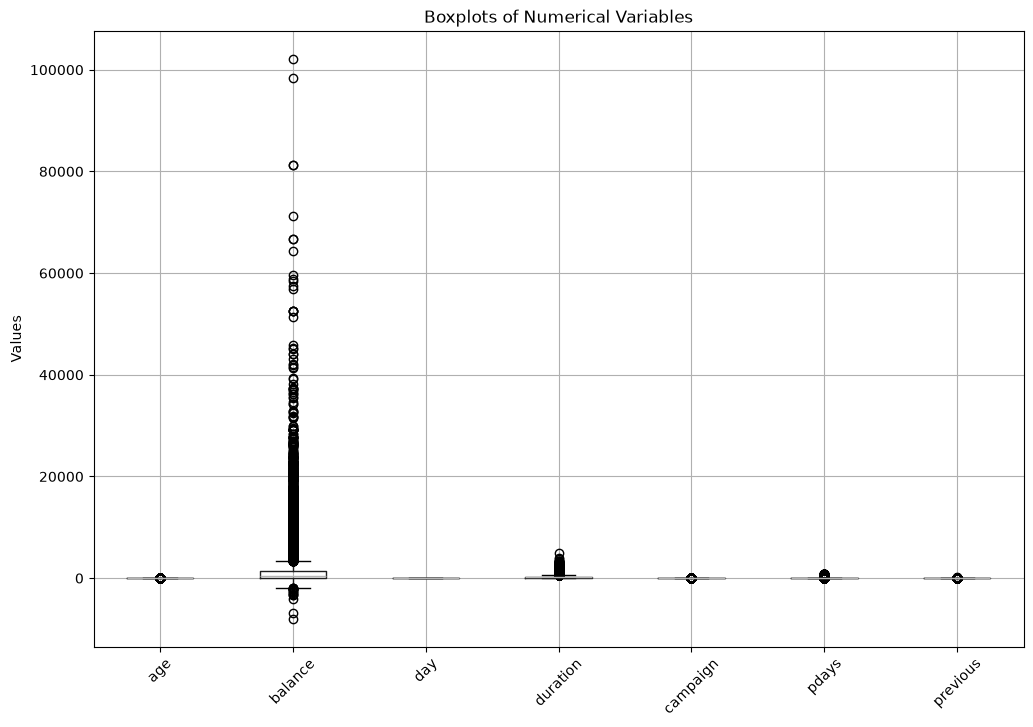

In [9]:
plt.figure(figsize=(12, 8))

df[numeric_columns].boxplot()

plt.title("Boxplots of Numerical Variables")
plt.xticks(rotation=45)
plt.ylabel("Values")
plt.show()

In [10]:

## 4.5 Statistical summary of numerical variables
df[numeric_columns].describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [11]:
## 4.6 Target variable distribution
print("Target Variable Distribution:")
print(df["y"].value_counts())

print("\nTarget Variable Percentage:")
print(df["y"].value_counts(normalize=True) * 100)



Target Variable Distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target Variable Percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


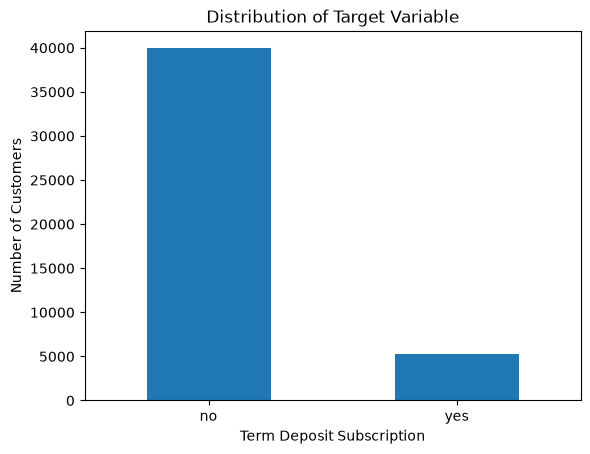

In [12]:
## 4.7 Target Variable Distribution Visualization
import matplotlib.pyplot as plt

df["y"].value_counts().plot(kind="bar")

plt.title("Distribution of Target Variable")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [13]:
## 4.8 Identify categorical columns
categorical_columns = df.select_dtypes(include=["object", "str"]).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

Categorical Columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


In [14]:
## 4.9 Encode target variable
df["y"] = df["y"].map({"no": 0, "yes": 1})

print(df["y"].value_counts())



y
0    39922
1     5289
Name: count, dtype: int64


In [15]:
## 4.10 Encode categorical features using one-hot encoding

categorical_features = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "month", "poutcome"
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)



Original shape: (45211, 17)
Encoded shape: (45211, 43)


In [16]:
## 4.11 Remove duration to avoid data leakage

df_encoded = df_encoded.drop(columns=["duration"])

print("Shape after removing duration:", df_encoded.shape)

Shape after removing duration: (45211, 42)


In [17]:
## 4.12 Separate features (X) and target (y)

X = df_encoded.drop(columns=["y"])
y = df_encoded["y"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (45211, 41)
y shape: (45211,)


In [18]:
## 4.13 Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (36168, 41)
X_test shape: (9043, 41)
y_train shape: (36168,)
y_test shape: (9043,)


In [19]:
## 4.14 Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (36168, 41)
Scaled testing shape: (9043, 41)


## 5. Algorithm Selection
Four supervised machine learning classification algorithms were selected for this project. Logistic Regression was selected as a baseline classification model. Decision Tree, Random Forest, and K-Nearest Neighbors (KNN) were selected to compare different classification approaches.

The selected algorithms are:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. K-Nearest Neighbors (KNN)

In [20]:
## 5.1 Logistic Regression
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


In [21]:
### 5.1.1 Model Prediction
# Make predictions using Logistic Regression

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Predictions generated successfully.")

Predictions generated successfully.


In [22]:
## 5.1.2 Evaluate Logistic Regression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)

# ROC-AUC
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression Evaluation")
print("--------------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)
print("ROC-AUC  :", roc_auc)

Logistic Regression Evaluation
--------------------------------
Accuracy : 0.8935087913303107
Precision: 0.6666666666666666
Recall   : 0.17958412098298676
F1-Score : 0.28294862248696945
ROC-AUC  : 0.7717278261579782


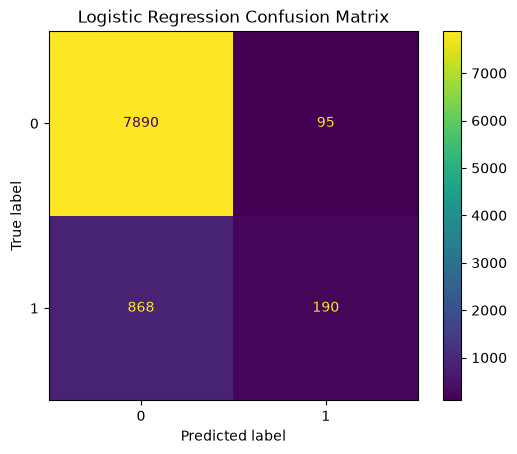

In [23]:
### 5.1.3 Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [24]:
### 5.1.4 Classification Report

# Generate classification report for Logistic Regression

from sklearn.metrics import classification_report

print("Logistic Regression Classification Report")
print("------------------------------------------")

print(classification_report(y_test, y_pred_logistic))

Logistic Regression Classification Report
------------------------------------------
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.67      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043



In [25]:
## 5.2 Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [26]:
## 5.2.1 Make predictions using the trained Decision Tree model
y_pred_dt = decision_tree_model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


In [27]:
## 5.2.2 Evaluate the Decision Tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Calculate evaluation metrics

accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

# Calculate ROC-AUC
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Evaluation")
print("--------------------------------")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1-Score :", f1_dt)
print("ROC-AUC  :", roc_auc_dt)

Decision Tree Evaluation
--------------------------------
Accuracy : 0.892734711931881
Precision: 0.691304347826087
Recall   : 0.1502835538752363
F1-Score : 0.2468944099378882
ROC-AUC  : 0.7052232861000008


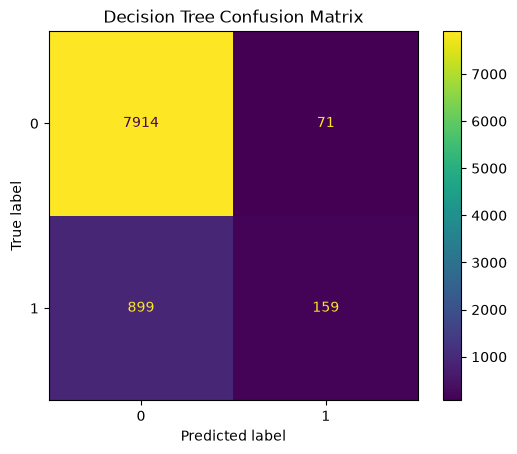

In [28]:
## 5.2.3 Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [29]:
## 5.2.4 Classification Report
from sklearn.metrics import classification_report

print("Decision Tree Classification Report")
print("--------------------------------")
print(classification_report(y_test, y_pred_dt))

Decision Tree Classification Report
--------------------------------
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.69      0.15      0.25      1058

    accuracy                           0.89      9043
   macro avg       0.79      0.57      0.59      9043
weighted avg       0.87      0.89      0.86      9043



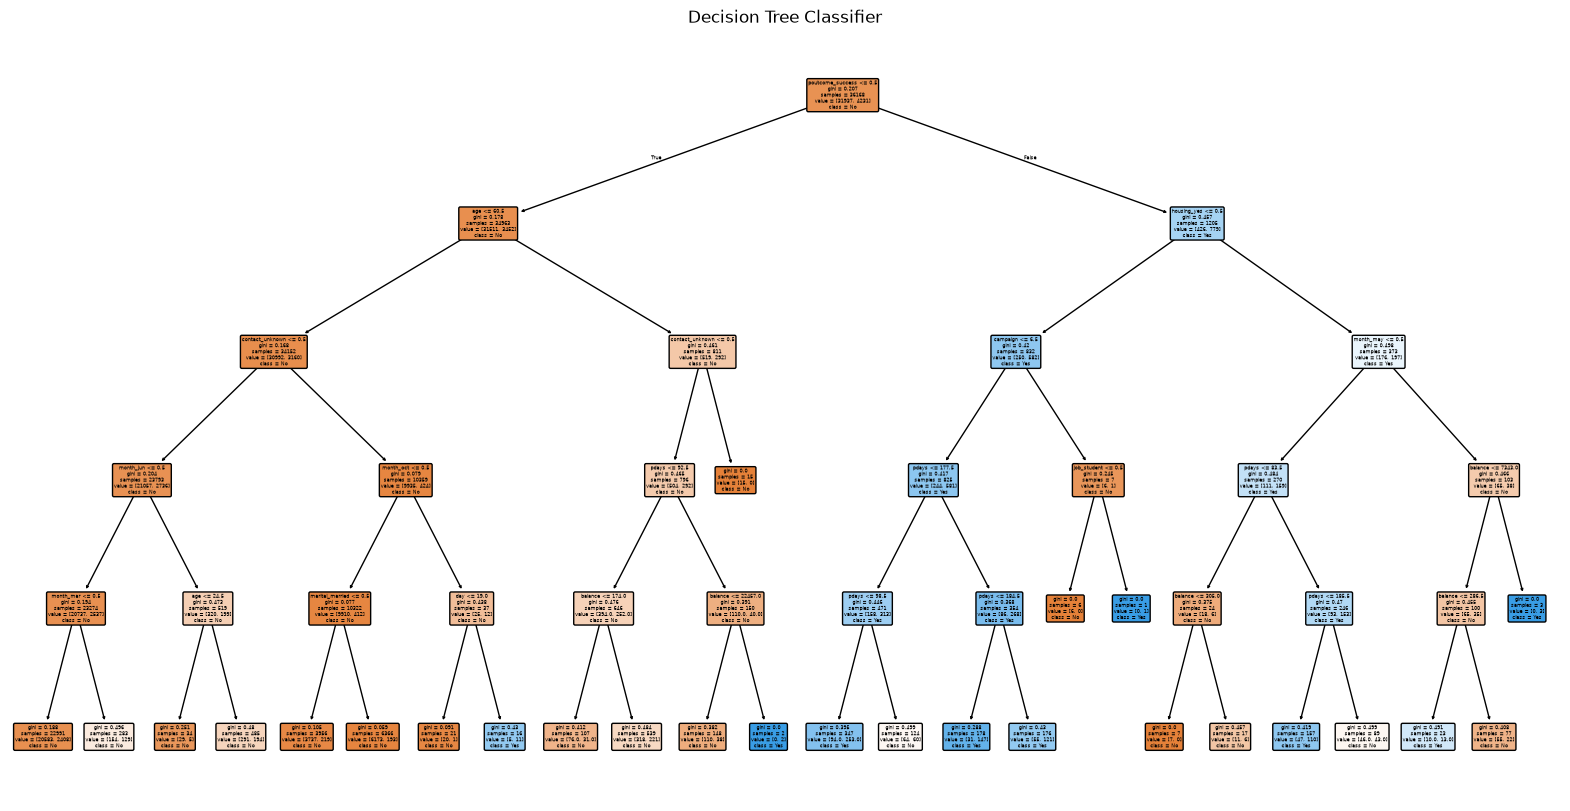

In [30]:

## 5.2.5 Visualize the Decision Tree
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    decision_tree_model,
    feature_names=X_train.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classifier")
plt.show()

In [31]:
## 5.3 Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [32]:
### 5.3.1 Model Prediction

# Make predictions using Random Forest

y_pred_rf = random_forest_model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


In [149]:
### 5.3.2 Evaluate Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

# Calculate ROC-AUC
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Evaluation")
print("--------------------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1-Score :", f1_rf)
print("ROC-AUC  :", roc_auc_rf)

Random Forest Evaluation
--------------------------------
Accuracy : 0.8943934534999447
Precision: 0.636604774535809
Recall   : 0.22684310018903592
F1-Score : 0.3344947735191638
ROC-AUC  : 0.7893865269592206


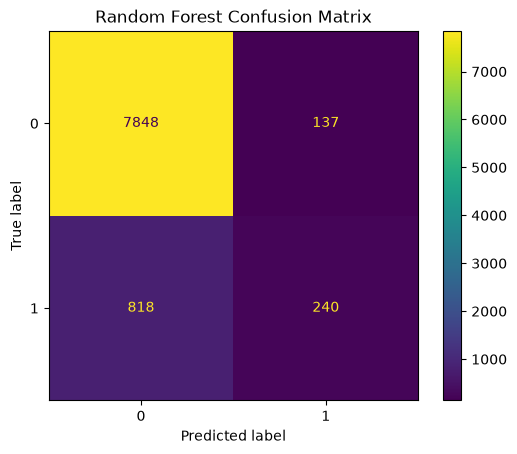

In [150]:
### 5.3.3 Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

In [151]:
### 5.3.4 Classification Report

from sklearn.metrics import classification_report

print("Random Forest Classification Report")
print("--------------------------------")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report
--------------------------------
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7985
           1       0.64      0.23      0.33      1058

    accuracy                           0.89      9043
   macro avg       0.77      0.60      0.64      9043
weighted avg       0.87      0.89      0.87      9043



In [152]:
## 5.4 K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


In [153]:
### 5.4.1 Model Prediction

# Make predictions using KNN

y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN predictions generated successfully.")

KNN predictions generated successfully.


In [154]:
### 5.4.2 Evaluate KNN

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

# Calculate ROC-AUC
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print("KNN Evaluation")
print("--------------------------------")
print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1-Score :", f1_knn)
print("ROC-AUC  :", roc_auc_knn)

KNN Evaluation
--------------------------------
Accuracy : 0.8899701426517749
Precision: 0.5665961945031712
Recall   : 0.2533081285444234
F1-Score : 0.35009797517962116
ROC-AUC  : 0.7099453962001058


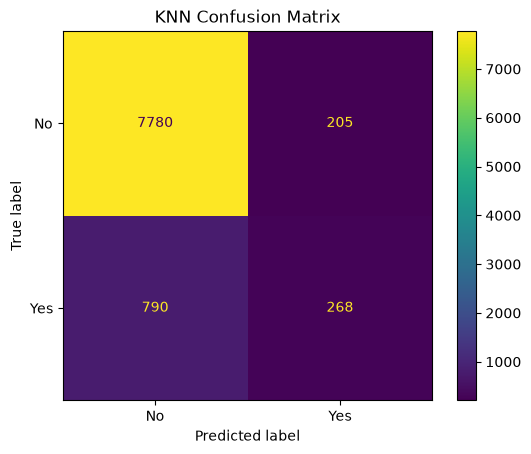

In [155]:
### 5.4.3 Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["No", "Yes"]
)

disp.plot()
plt.title("KNN Confusion Matrix")
plt.show()

In [156]:
### 5.4.4 Classification Report

from sklearn.metrics import classification_report

print("KNN Classification Report")
print("--------------------------------")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No", "Yes"]
))

KNN Classification Report
--------------------------------
              precision    recall  f1-score   support

          No       0.91      0.97      0.94      7985
         Yes       0.57      0.25      0.35      1058

    accuracy                           0.89      9043
   macro avg       0.74      0.61      0.64      9043
weighted avg       0.87      0.89      0.87      9043



In [157]:
## 5.5 Model Comparison

### 5.5.1 Compare Model Performance

import pandas as pd

# Create a comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf,
        accuracy_knn
    ],
    "Precision": [
        precision,
        precision_dt,
        precision_rf,
        precision_knn
    ],
    "Recall": [
        recall,
        recall_dt,
        recall_rf,
        recall_knn
    ],
    "F1-Score": [
        f1,
        f1_dt,
        f1_rf,
        f1_knn
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_dt,
        roc_auc_rf,
        roc_auc_knn
    ]
})

print("Model Performance Comparison")
print("--------------------------------")

display(model_comparison)


Model Performance Comparison
--------------------------------


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.893509,0.666667,0.179584,0.282949,0.771728
1,Decision Tree,0.892735,0.691304,0.150284,0.246894,0.705223
2,Random Forest,0.894393,0.636605,0.226843,0.334495,0.789387
3,KNN,0.889970,0.566596,0.253308,0.350098,0.709945


In [158]:
## 5.5.2 Feature Importance

import pandas as pd
from sklearn.inspection import permutation_importance

# Logistic Regression
logistic_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": abs(logistic_model.coef_[0])
}).sort_values(by="Importance", ascending=False)

print("Top 10 Features - Logistic Regression")
display(logistic_importance.head(10))


# Decision Tree
dt_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": decision_tree_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 10 Features - Decision Tree")
display(dt_importance.head(10))


# Random Forest
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 10 Features - Random Forest")
display(rf_importance.head(10))


# KNN - Permutation Importance
knn_permutation = permutation_importance(
    knn_model,
    X_test_scaled,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="f1"
)

knn_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": knn_permutation.importances_mean
}).sort_values(by="Importance", ascending=False)

print("Top 10 Features - KNN")
display(knn_importance.head(10))

Top 10 Features - Logistic Regression


,Feature,Importance
26,contact_unknown,0.603304
39,poutcome_success,0.408229
27,month_aug,0.287476
23,housing_yes,0.256587
3,campaign,0.256094
31,month_jul,0.250447
35,month_nov,0.243544
34,month_may,0.221090
30,month_jan,0.191026
24,loan_yes,0.138593


Top 10 Features - Decision Tree


,Feature,Importance
39,poutcome_success,0.616354
0,age,0.103575
26,contact_unknown,0.073308
32,month_jun,0.067428
33,month_mar,0.060776
4,pdays,0.029072
23,housing_yes,0.013339
1,balance,0.009901
2,day,0.006558
34,month_may,0.006362


Top 10 Features - Random Forest


,Feature,Importance
1,balance,0.184213
0,age,0.155428
2,day,0.133761
3,campaign,0.063056
39,poutcome_success,0.057146
4,pdays,0.050929
5,previous,0.025100
23,housing_yes,0.022755
19,education_secondary,0.017904
14,job_technician,0.014930


Top 10 Features - KNN


,Feature,Importance
39,poutcome_success,0.131584
33,month_mar,0.023492
2,day,0.023101
27,month_aug,0.020883
26,contact_unknown,0.020586
31,month_jul,0.020421
37,month_sep,0.016978
23,housing_yes,0.016073
18,marital_single,0.015534
20,education_tertiary,0.013586


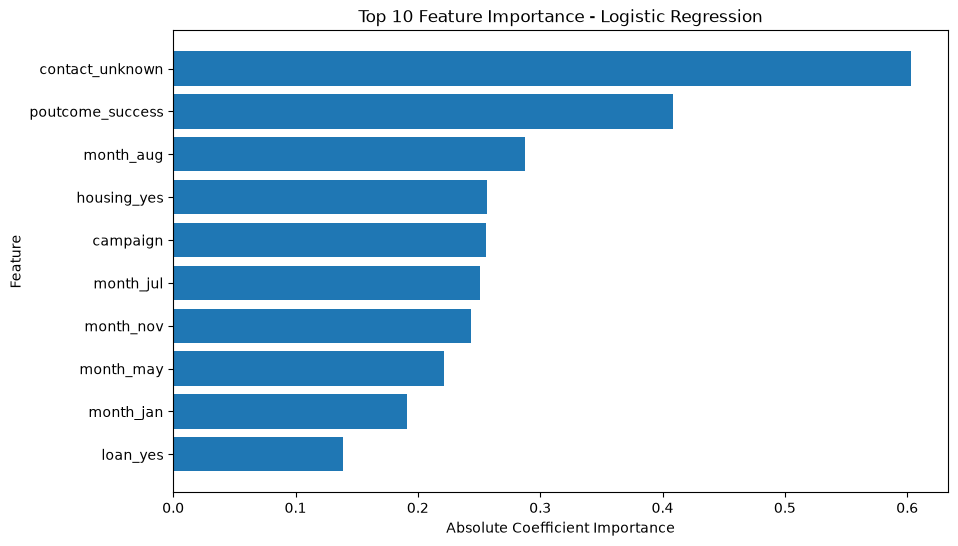

In [159]:
## 5.5.3 Feature Importance Visualization
# Logistic Regression - Top 10 Features

top_logistic = logistic_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_logistic["Feature"],
    top_logistic["Importance"]
)

plt.title("Top 10 Feature Importance - Logistic Regression")
plt.xlabel("Absolute Coefficient Importance")
plt.ylabel("Feature")

plt.show()

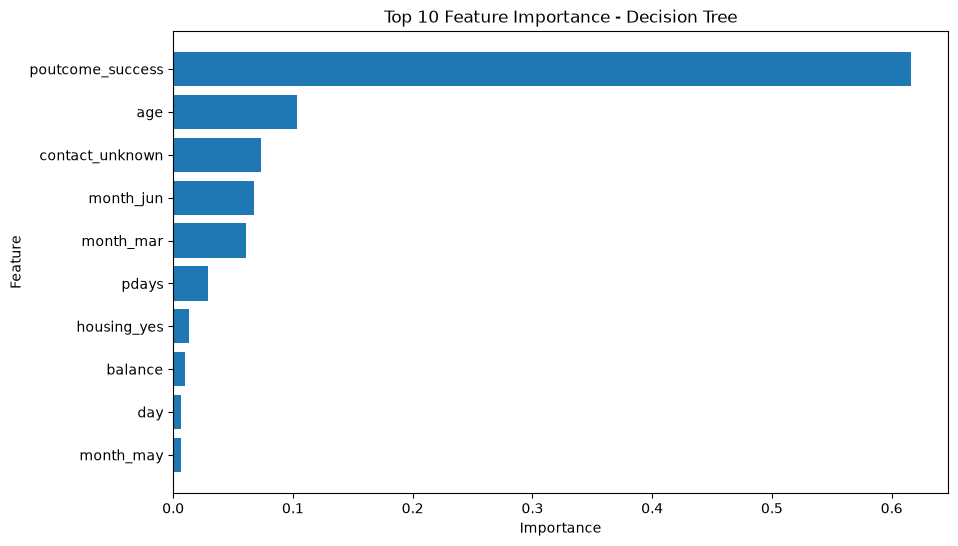

In [160]:
# Decision Tree - Top 10 Features

top_dt = dt_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_dt["Feature"],
    top_dt["Importance"]
)

plt.title("Top 10 Feature Importance - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

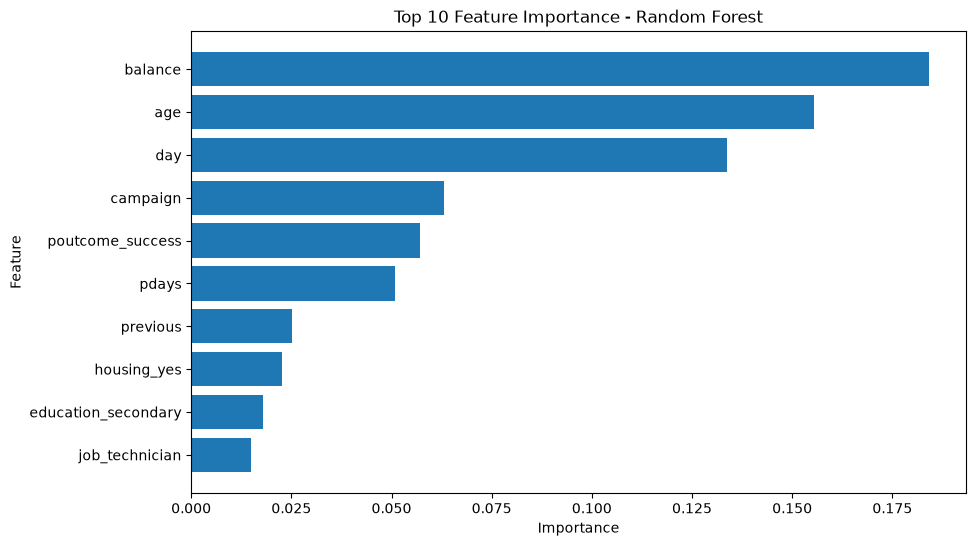

In [161]:
# Random Forest - Top 10 Features
import matplotlib.pyplot as plt

top_rf = rf_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_rf["Feature"],
    top_rf["Importance"]
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()


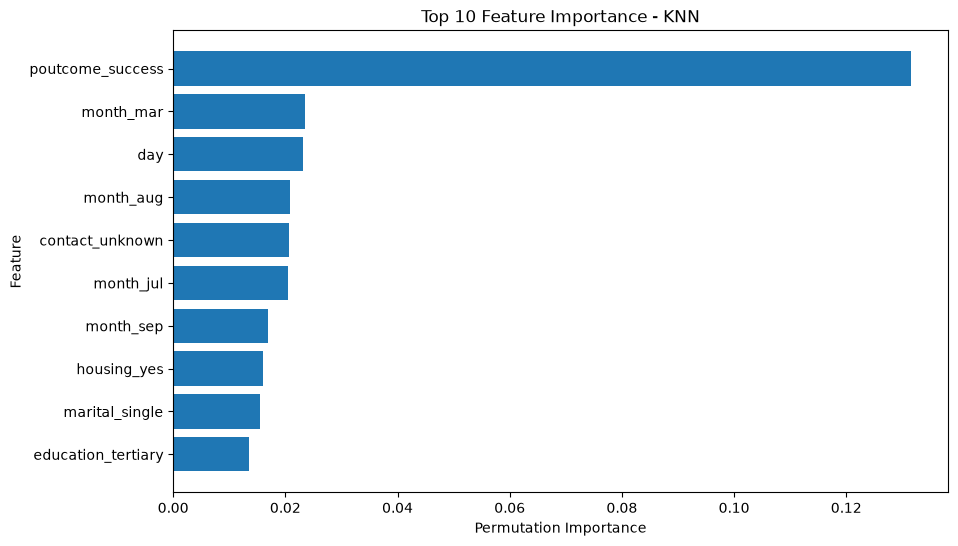

In [162]:

# KNN - Top 10 Features

top_knn = knn_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_knn["Feature"],
    top_knn["Importance"]
)

plt.title("Top 10 Feature Importance - KNN")
plt.xlabel("Permutation Importance")
plt.ylabel("Feature")

plt.show()

### 5.5.4 Interpretation of Feature Selection (Before Tuning)

The feature importances in this section were taken from the models before any hyperparameter tuning and before dealing with class imbalance. The tuned version of the Random Forest is discussed separately in Section 5.5.9.

The feature importance results show that different machine learning models highlighted features as important for predicting whether a customer will subscribe to a term deposit. This is because each model uses a different method to find relationships between the input features and the target variable.

For Logistic Regression, feature importance was calculated using the values of the model coefficients. The important features were `contact_unknown`, `poutcome_success`, `month_aug`, `housing_yes`, and `campaign`. For the Decision Tree model, the important features were `poutcome_success`, `age`, `contact_unknown`, `month_jun`, and `month_mar`. Random Forest found `balance`, `age`, `day`, `campaign`, and `poutcome_success` to be among the important features.

For KNN, permutation importance was used because KNN does not have a built-in way to calculate feature importance. The important features according to permutation importance were `poutcome_success`, `month_mar`, `day`, `month_aug`, `contact_unknown`, and `month_jul`. This method checks how the model's performance changes when individual features are shuffled randomly. Features that lead to a drop in performance are considered more important.

Overall, the results show that previous campaign results, customer details, contact methods, account balance, campaign details, and the month of contact are important when predicting whether a customer will subscribe to a term deposit. These results can help the bank understand which customer and campaign features are more important when identifying potential subscribers and creating targeted marketing strategies.


In [163]:
### 5.5.5 Hyperparameter Tuning Using Grid Search
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define models, hyperparameter grids, and scaling requirements
searches = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ),
        {
            "C": [0.01, 0.1, 1, 10]
        },
        True
    ),

    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ),
        {
            "max_depth": [3, 5, 7, 10],
            "min_samples_leaf": [10, 50, 100]
        },
        False
    ),

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        {
            "n_estimators": [100, 200],
            "max_depth": [8, 12],
            "min_samples_leaf": [5, 20]
        },
        False
    ),

    "KNN": (
        ImbPipeline([
            ("smote", SMOTE(random_state=42)),
            ("knn", KNeighborsClassifier())
        ]),
        {
            "knn__n_neighbors": [5, 15, 25],
            "knn__weights": ["uniform", "distance"]
        },
        True
    )
}

# Store the best tuned models
tuned_models = {}

# Perform Grid Search for each model
for name, (model, grid, use_scaled) in searches.items():

    # Use scaled data for Logistic Regression and KNN
    Xtr = X_train_scaled if use_scaled else X_train

    # Perform hyperparameter tuning using Grid Search and 5-fold CV
    gs = GridSearchCV(
        estimator=model,
        param_grid=grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    # Fit the model and search for the best hyperparameters
    gs.fit(Xtr, y_train)

    # Store the tuned model and scaling information
    tuned_models[name] = (gs, use_scaled)

    # Display the best parameters and cross-validation F1-score
    print(
        f"{name}: "
        f"best params = {gs.best_params_}, "
        f"CV F1 = {gs.best_score_:.4f}"
    )

Logistic Regression: best params = {'C': 0.01}, CV F1 = 0.3749
Decision Tree: best params = {'max_depth': 7, 'min_samples_leaf': 10}, CV F1 = 0.4251
Random Forest: best params = {'max_depth': 12, 'min_samples_leaf': 5, 'n_estimators': 100}, CV F1 = 0.4409
KNN: best params = {'knn__n_neighbors': 25, 'knn__weights': 'distance'}, CV F1 = 0.3505


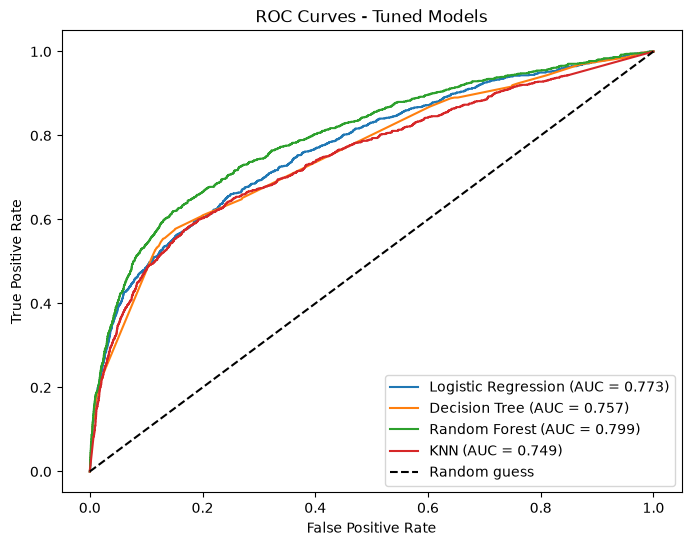

,Model,CV F1,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.3749,0.7569,0.2687,0.6257,0.3759,0.7726
1,Decision Tree,0.4251,0.8306,0.3564,0.5558,0.4343,0.7572
2,Random Forest,0.4409,0.8185,0.3468,0.6238,0.4458,0.7988
3,KNN,0.3505,0.7325,0.2514,0.6503,0.3626,0.7493


In [164]:
## 5.5.6 Evaluate tuned models on the test set
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)

rows = []
plt.figure(figsize=(8, 6))
for name, (gs, use_scaled) in tuned_models.items():
    Xte = X_test_scaled if use_scaled else X_test
    pred = gs.predict(Xte)
    prob = gs.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(y_test, prob)
    rows.append({
        "Model": name,
        "CV F1": gs.best_score_,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": auc,
    })
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Tuned Models")
plt.legend()
plt.savefig("roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

tuned_comparison = pd.DataFrame(rows).round(4)
display(tuned_comparison)

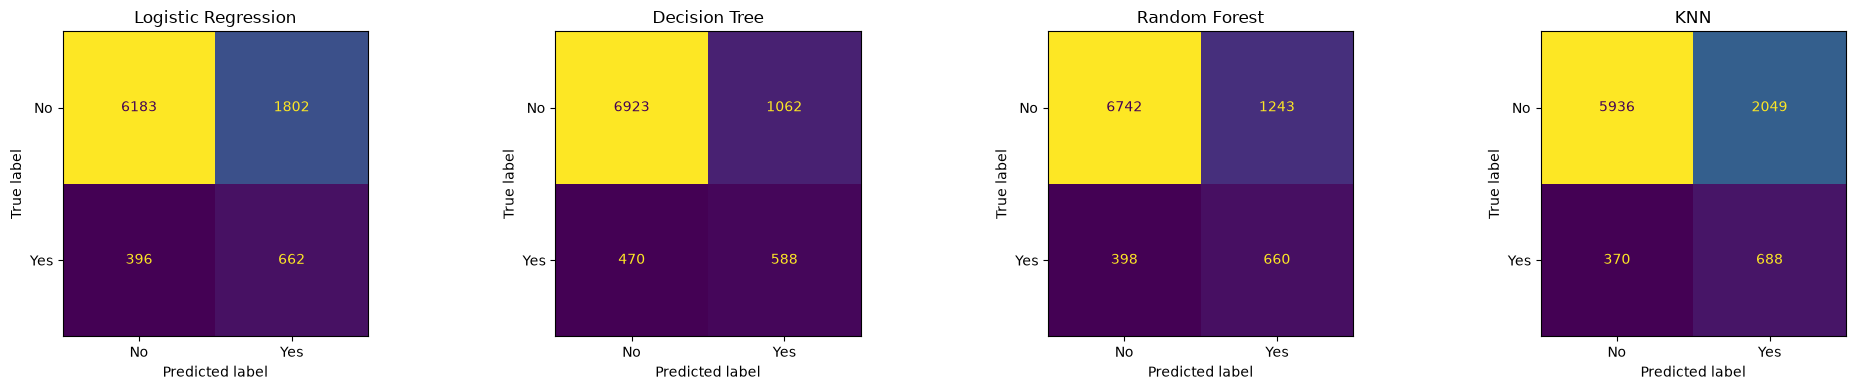

In [165]:
## 5.5.7 Confusion matrices - tuned models
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, (gs, use_scaled)) in zip(axes, tuned_models.items()):
    Xte = X_test_scaled if use_scaled else X_test
    ConfusionMatrixDisplay.from_predictions(
        y_test, gs.predict(Xte),
        display_labels=["No", "Yes"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("confusion_matrices_tuned.png", dpi=200, bbox_inches="tight")
plt.show()

,Feature,Importance
39,poutcome_success,0.134664
26,contact_unknown,0.116920
0,age,0.081750
4,pdays,0.078326
23,housing_yes,0.073052
1,balance,0.071373
2,day,0.060917
3,campaign,0.036494
5,previous,0.035101
40,poutcome_unknown,0.031465


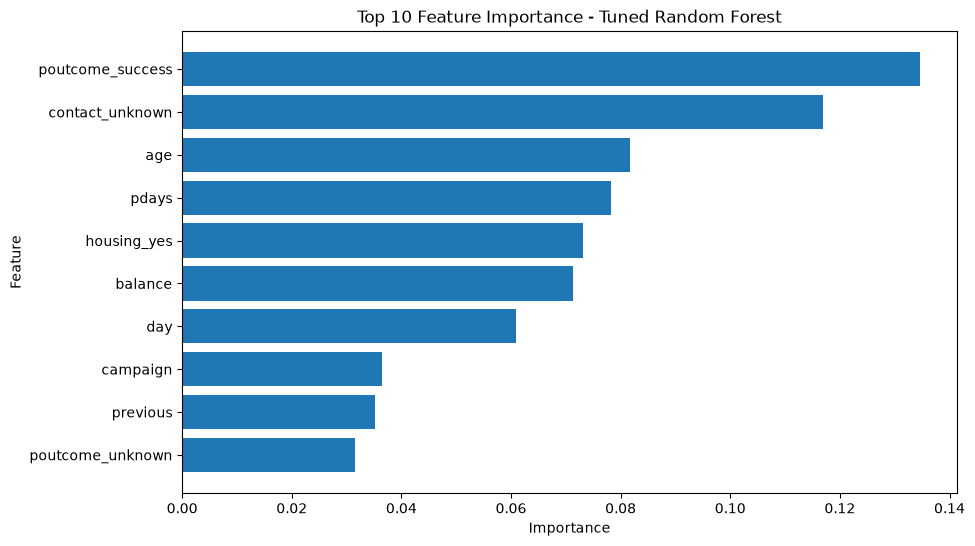

In [166]:
## 5.5.8 Feature importance - tuned Random Forest
best_rf = tuned_models["Random Forest"][0].best_estimator_

rf_tuned_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(rf_tuned_importance.head(10))

top = rf_tuned_importance.head(10).sort_values(by="Importance", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(top["Feature"], top["Importance"])
plt.title("Top 10 Feature Importance - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.savefig("rf_tuned_importance.png", dpi=200, bbox_inches="tight")
plt.show()


### 5.5.9 Feature Importance of the Tuned Random Forest
The tuned Random Forest, which was selected as the best model, ranked poutcome_success (0.135), contact_unknown (0.117), age (0.082), pdays (0.078) and housing_yes (0.073) as its most important features. Feature importance shows how much a feature contributes to the predictions, but it does not show in which direction the feature affects subscription. Therefore, the subscription rate of each category was calculated directly from the data.

Customers whose previous campaign outcome was a success subscribed at a rate of 64.73%, compared with 9.16% for customers with an unknown previous outcome. Customers whose contact type was unknown subscribed at only 4.07%, while cellular contacts subscribed at 14.92%. Customers without a housing loan subscribed at 16.7%, compared with 7.7% for those with a housing loan.

These results suggest that the bank could prioritise customers with a successful previous campaign and those without a housing loan. These are associations found in the data and do not prove that these features cause customers to subscribe. For example, the low rate for unknown contact type could be due to how the data was recorded rather than the behaviour of those customers.

In [167]:
## 5.5.10  Subscription rate by key features (direction check)
for col in ["poutcome", "contact", "housing"]:
    print(f"\nSubscription rate by {col}:")
    print((df.groupby(col)["y"].mean() * 100).round(2).sort_values(ascending=False))


Subscription rate by poutcome:
poutcome
success    64.73
other      16.68
failure    12.61
unknown     9.16
Name: y, dtype: float64

Subscription rate by contact:
contact
cellular     14.92
telephone    13.42
unknown       4.07
Name: y, dtype: float64

Subscription rate by housing:
housing
no     16.7
yes     7.7
Name: y, dtype: float64


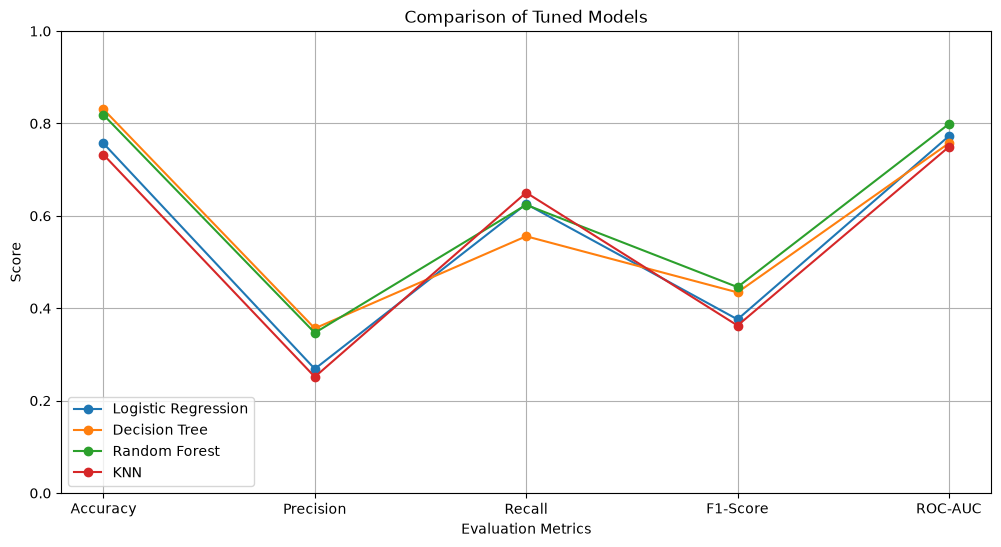

In [168]:
## 5.6.1 Model Performance Visualization (after tuning)
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

plt.figure(figsize=(12, 6))
for _, row in tuned_comparison.iterrows():
    plt.plot(metrics, [row[m] for m in metrics], marker="o", label=row["Model"])

plt.title("Comparison of Tuned Models")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.savefig("tuned_model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


In [169]:
## 5.6.2 Before vs After tuning
before = model_comparison.set_index("Model")[["Recall", "F1-Score", "ROC-AUC"]]
after = tuned_comparison.set_index("Model")[["Recall", "F1-Score", "ROC-AUC"]]
display(before.join(after, lsuffix=" (before)", rsuffix=" (after)").round(4))

,Recall (before),F1-Score (before),ROC-AUC (before),Recall (after),F1-Score (after),ROC-AUC (after)
Model,,,,,,
Logistic Regression,0.1796,0.2829,0.7717,0.6257,0.3759,0.7726
Decision Tree,0.1503,0.2469,0.7052,0.5558,0.4343,0.7572
Random Forest,0.2268,0.3345,0.7894,0.6238,0.4458,0.7988
KNN,0.2533,0.3501,0.7099,0.6503,0.3626,0.7493


### 5.6.3 Interpretation of Results

Before handling class imbalance, all four models achieved approximately 89% accuracy. However their recall values were between 0.15 and 0.25. This indicates that the models missed the majority of customers who truly subscribed. Since non‑subscribers dominate the dataset a model can obtain an accuracy by predicting "No" for almost every case. Therefore, accuracy alone was not considered sufficient for evaluating model performance.

After applying class weights to Logistic Regression, Decision Tree and Random Forest or using SMOTE for KNN and then running GridSearchCV with cross‑validation recall increased to a range between 0.56 and 0.65 across all models. This improvement came at a cost: accuracy fell to between 0.73 and 0.83 and precision dropped to between 0.25 and 0.36. The models began to label customers as likely subscribers and some of those labels were incorrect. ROC-AUC values changed slightly—for example, from 0.7717 to 0.7726 for Logistic Regression—indicating that the improvement in recall was mainly associated with class-imbalance handling methods and model tuning rather than a large improvement in the models' ability to rank customers by their predicted probabilities.

Among the tuned models Random Forest delivered the F1‑Score of 0.4458 and the highest ROC‑AUC of 0.7988. Random Forest also achieved a recall of 0.6238 and a precision of 0.3468. The cross‑validation F1‑Score for Random Forest was 0.4409 almost identical to its test F1‑Score which suggests that Random Forest is stable and not overfitted. Decision Tree reached the precision of 0.3564 and the highest accuracy of 0.8306 yet its recall was only 0.5558. KNN had the recall of 0.6503 but the lowest precision of 0.2514 and the lowest ROC‑AUC of 0.7493 and it produced the largest number of false positives, 2,049. Logistic Regression produced a recall of 0.6257 and an F1-Score of 0.3759.

For the Random Forest the confusion matrix records 660 true positives, 398 false negatives, 1,243 false positives and 6,742 true negatives. Thus Random Forest identified 62 percent of the real subscribers. Of the customers that Random Forest predicted as subscribers 35 percent actually subscribed.This compares with an overall subscription rate of about 11.7% in the test set.

### 5.6.4 Best Model Selection

Based on the tuned results, Random Forest was selected as the most suitable model for this business problem. It achieved the highest F1-Score (0.4458) and the highest ROC-AUC (0.7988) of the four models. Its recall of 0.6238 was close to the highest recall (KNN, 0.6503), while its precision (0.3468) was much better than KNN's (0.2514).

The main objective is to find customers who are likely to subscribe, so recall matters. However, precision matters too, because every false positive is a wasted call. KNN found slightly more subscribers (370 false negatives against 398 for Random Forest), but it produced 2,049 false positives compared with 1,243 for Random Forest. Random Forest therefore gives a better balance between finding subscribers and avoiding unnecessary contacts. Decision Tree had fewer false positives (1,062) but missed more subscribers (470 false negatives) and had a lower F1-Score (0.4343) and ROC-AUC (0.7572).

The cross-validation F1-Score of Random Forest (0.4409) was very close to its test F1-Score (0.4458), which indicates that the model generalises well and is not overfitted.

The final choice depends on the bank's costs. If missing a subscriber is much more costly than an extra call, a model with higher recall could be preferred, and if calls are expensive, a model with higher precision such as Decision Tree could be considered. Considering both, Random Forest was selected as the final model.

In [170]:
## Final Model - Tuned Random Forest
from sklearn.metrics import classification_report

final_model = tuned_models["Random Forest"][0].best_estimator_
final_predictions = final_model.predict(X_test)

print("Tuned Random Forest - Classification Report")
print(classification_report(y_test, final_predictions, target_names=["No", "Yes"]))

comparison = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": final_predictions[:10]
})
display(comparison)

Tuned Random Forest - Classification Report
              precision    recall  f1-score   support

          No       0.94      0.84      0.89      7985
         Yes       0.35      0.62      0.45      1058

    accuracy                           0.82      9043
   macro avg       0.65      0.73      0.67      9043
weighted avg       0.87      0.82      0.84      9043



,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,1,1
8,0,1
9,0,0


## 6. Conclusion
This study applied Logistic Regression, Decision Tree, Random Forest and KNN to predict whether a bank customer would subscribe to a term deposit, using the UCI Bank Marketing dataset. The `duration` feature was removed to avoid data leakage, and the models were evaluated with Accuracy, Precision, Recall, F1-Score and ROC-AUC.

With default settings, all models reached about 89% accuracy but recall was only 0.15 to 0.25, because most customers in the data did not subscribe. After applying class weights or SMOTE, GridSearchCV and 5-fold cross-validation, recall rose to between 0.56 and 0.65, at the cost of lower precision and accuracy.

The tuned Random Forest was selected as the best model (F1-Score 0.4458, ROC-AUC 0.7988, recall 0.6238). It identified about 62% of actual subscribers, and about 35% of the customers it flagged did subscribe, against an overall rate of about 11.7%. The most important features were poutcome_success, contact_unknown, age, pdays and housing_yes. Customers with a successful previous campaign subscribed at 64.73%, while those with unknown contact type subscribed at only 4.07%.

The bank can use the model to rank customers by predicted probability and contact the highest-ranked ones first, which reduces unnecessary calls. The main limitations are the low precision (many false positives), the fact that feature importance shows which features matter but not the direction of their effect, and that the data comes from a single bank. Future work could include tuning the decision threshold using the real cost of a call and of a missed subscriber, testing other algorithms such as gradient boosting, and validating the model on newer campaign data.